# 02 – Modelagem e avaliação por evento (MetroPT-3)

**Objetivo:** treinar modelos de predição de falha nas variantes E0, E1 e E2 do pipeline e compará-los **por evento**.

Regras deste notebook:
- **Divisão por falhas (forward-chaining):** cada fold treina só com o passado e testa em uma falha, com embargo de X horas.
- **Mesma população de teste:** todas as variantes são avaliadas nos mesmos minutos (os da E2), com os mesmos rótulos. Sem isso, a diferença entre variantes viria também do conjunto de teste, não só do pipeline.
- **E0–E2 sem tratamento de desbalanceamento** (`BALANCE = "none"`), para isolar o efeito da engenharia de dados. O tratamento (E3) é uma rodada separada com `BALANCE = "class_weight"`.
- **Ponto de operação:** limiar escolhido para uma taxa fixa de falsos positivos nos minutos normais do teste (mesmo orçamento de alarmes para todos). É uma ferramenta de comparação, não uma regra de implantação.
- Com apenas 4 falhas (3 folds), os resultados são **descritivos**: sem teste de significância.

In [ ]:
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import config
from evaluation import circular_shift_null, event_metrics, fixed_fpr_threshold
from splits import forward_chaining_folds

# --- Parâmetros da rodada -------------------------------------------------
HORIZON = 24               # horas; precisa existir em data/gold (ex.: e2_h24)
BALANCE = "none"          # "none" (E0-E2)  |  "class_weight" (E3)
FPR_TARGET = 0.01         # fração de minutos normais que podem ficar em alarme
COMMON_EVAL = True        # avalia todas as variantes nos mesmos minutos (os da E2)
N_TREES = 100
N_SHIFTS = 200            # rotações do baseline de acaso
TRAIN_EVAL_ROWS = 100_000 # amostra do treino para a PR-AUC em amostra
SEED = config.SEED
EMBARGO = 24              # horas entre o fim do treino e o início do teste
IGNORED = {"c0"}          # índice do CSV: nunca usar como feature
VARIANTS = {"E0": f"e0_h{HORIZON}", "E1": f"e1_h{HORIZON}", "E2": f"e2_h{HORIZON}"}


## 1. Falhas e folds

In [20]:
rep = pd.read_csv(config.FAILURE_REPORT, parse_dates=["start_time", "end_time"]).sort_values("start_time")
failures = [
    {"id": int(r.failure_id), "start": r.start_time.to_pydatetime(), "end": r.end_time.to_pydatetime()}
    for r in rep.itertuples()
]
fail_start = {f["id"]: pd.Timestamp(f["start"]) for f in failures}
folds = forward_chaining_folds(failures, EMBARGO)
for f in folds:
    print(f.name, "| treino até", f.train_end, "| teste de", f.test_start, "até", f.test_end)

fold_falha_2 | treino até 2020-04-18 23:59:00 | teste de 2020-04-19 23:59:00 até 2020-05-30 06:00:00
fold_falha_3 | treino até 2020-05-30 06:00:00 | teste de 2020-05-31 06:00:00 até 2020-06-07 14:30:00
fold_falha_4 | treino até 2020-06-07 14:30:00 | teste de 2020-06-08 14:30:00 até 2020-07-15 19:00:00


## 2. Dados (Gold)

In [21]:
data = {}
for name, folder in VARIANTS.items():
    df = pd.read_parquet(config.GOLD_DIR / folder)
    df["ts"] = pd.to_datetime(df["ts"]).dt.tz_localize(None)
    data[name] = df.sort_values("ts").reset_index(drop=True)
    print(f"{name}: {len(df):>9,} linhas | positivos {int(df.label.sum()):>6,} ({df.label.mean():.2%})")

META = {"ts", "label", "failure_id_ahead"} | IGNORED
def feature_columns(df):
    present = IGNORED & set(df.columns)
    if present:
        print("AVISO: colunas ignoradas presentes na Gold (reexecute Silver e Gold):", present)
    return [c for c in df.columns if c not in META]

for name, df in data.items():
    feats = feature_columns(df)
    assert not df[feats].isna().any().any(), f"{name}: há nulos nas features"
    print(name, "->", len(feats), "features")

# Rótulos de referência (E2) e minutos comuns
ref_label = data["E2"].set_index("ts")["label"]
ref_index = set(ref_label.index)
print("Minutos comuns de avaliação:", len(ref_index))

E0: 1,486,994 linhas | positivos 16,654 (1.12%)
E1:   247,428 linhas | positivos  2,880 (1.16%)
E2:   211,940 linhas | positivos  2,880 (1.36%)
E0 -> 15 features
E1 -> 15 features
E2 -> 59 features
Minutos comuns de avaliação: 211940


## 3. Modelos e avaliação por fold

Para a E0 (leituras de 10 s), os scores são agregados por minuto (média) antes de avaliar, para ficar na mesma unidade das demais.

In [22]:
def make_models():
    cw = "balanced" if BALANCE == "class_weight" else None
    return {
        "LogReg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight=cw)),
        "RandomForest": RandomForestClassifier(
            n_estimators=N_TREES, max_depth=14, min_samples_leaf=20,
            class_weight="balanced_subsample" if cw else None, n_jobs=-1, random_state=SEED),
        "LightGBM": LGBMClassifier(
            n_estimators=300, learning_rate=0.05, num_leaves=31, class_weight=cw,
            random_state=SEED, verbose=-1, n_jobs=-1),
    }

def prepare_eval(variant, test, score):
    t = test[["ts", "label"]].copy()
    t["score"] = score
    if variant == "E0":
        t["ts"] = t["ts"].dt.floor("min")
        t = t.groupby("ts", as_index=False).agg(score=("score", "mean"), label=("label", "max"))
    if COMMON_EVAL:
        t = t[t["ts"].isin(ref_index)].copy()
        t["label"] = t["ts"].map(ref_label).astype(int)
    return t.sort_values("ts").reset_index(drop=True)

rows, preds = [], {}
for variant, df in data.items():
    feats = feature_columns(df)
    for fold in folds:
        train = df[df["ts"] <= fold.train_end]
        test = df[(df["ts"] > fold.test_start) & (df["ts"] <= fold.test_end)]
        if train["label"].sum() == 0 or test.empty:
            print(f"{variant} {fold.name}: sem positivos no treino ou teste vazio; pulando")
            continue
        for mname, model in make_models().items():
            model.fit(train[feats], train["label"])
            t = prepare_eval(variant, test, model.predict_proba(test[feats])[:, 1])
            if t["label"].sum() == 0:
                print(f"{variant} {fold.name}: sem positivos nos minutos comuns; pulando")
                break
            thr = fixed_fpr_threshold(t["score"], t["label"], FPR_TARGET)
            m = event_metrics(t, "score", thr, fail_start[fold.test_failure_id])
            pr = average_precision_score(t["label"], t["score"])
            prev = t["label"].mean()
            # PR-AUC em amostra (treino): separa "não aprende nada" de "aprende e não generaliza"
            tr = train.sample(min(len(train), TRAIN_EVAL_ROWS), random_state=SEED)
            pr_train = average_precision_score(tr["label"], model.predict_proba(tr[feats])[:, 1])
            # Baseline de acaso por rotação circular dos scores
            null = circular_shift_null(t, "score", FPR_TARGET, n_shifts=N_SHIFTS, seed=SEED)
            rows.append({
                "variante": variant, "modelo": mname, "falha_testada": fold.test_failure_id,
                "minutos_teste": len(t), "positivos": int(t["label"].sum()),
                "prevalencia": prev, "pr_auc": pr, "lift": pr / prev,
                "pr_auc_treino": pr_train, "prevalencia_treino": tr["label"].mean(),
                "pr_auc_acaso_mediana": null["pr_auc"].median(),
                "p_pr_auc": (null["pr_auc"] >= pr).mean(),
                "deteccao_por_acaso": null["detected"].mean(),
                "limiar": thr, **m,
            })
            preds[(variant, mname, fold.test_failure_id)] = (t, thr)
        print(f"{variant} {fold.name} concluído")

res = pd.DataFrame(rows)
res.round(4)

E0 fold_falha_2 concluído
E0 fold_falha_3 concluído
E0 fold_falha_4 concluído
E1 fold_falha_2 concluído
E1 fold_falha_3 concluído
E1 fold_falha_4 concluído
E2 fold_falha_2 concluído
E2 fold_falha_3 concluído
E2 fold_falha_4 concluído


,variante,modelo,falha_testada,minutos_teste,positivos,prevalencia,pr_auc,lift,pr_auc_treino,prevalencia_treino,pr_auc_acaso_mediana,p_pr_auc,deteccao_por_acaso,limiar,detected,lead_h,false_alarm_episodes,false_alarms_per_day,alarm_minutes
0,E0,LogReg,2,36065,720,0.0200,0.0151,0.7588,0.4112,0.0066,0.0238,0.790,0.525,0.0360,0.0,NaN,35,1.3975,354
1,E0,RandomForest,2,36065,720,0.0200,0.0187,0.9375,0.8450,0.0066,0.0188,0.530,0.120,0.0362,0.0,NaN,9,0.3594,2305
2,E0,LightGBM,2,36065,720,0.0200,0.0269,1.3496,0.8450,0.0066,0.0227,0.265,0.880,0.0000,0.0,NaN,169,6.7478,354
3,E0,LogReg,3,5863,720,0.1228,0.1194,0.9726,0.0453,0.0094,0.1242,0.765,0.810,0.0226,1.0,8.0000,19,4.6666,58
4,E0,RandomForest,3,5863,720,0.1228,0.0718,0.5845,0.6502,0.0094,0.1282,0.990,0.705,0.1367,1.0,0.0333,9,2.2105,53
5,E0,LightGBM,3,5863,720,0.1228,0.0746,0.6074,0.7134,0.0094,0.1225,0.990,0.655,0.3530,0.0,NaN,14,3.4385,52
6,E0,LogReg,4,38450,720,0.0187,0.0358,1.9092,0.0440,0.0142,0.0151,0.110,0.110,0.1417,0.0,NaN,1,0.0375,403
7,E0,RandomForest,4,38450,720,0.0187,0.0114,0.6067,0.4871,0.0142,0.0205,1.000,0.400,0.0924,0.0,NaN,39,1.4606,378
8,E0,LightGBM,4,38450,720,0.0187,0.0104,0.5541,0.5207,0.0142,0.0203,1.000,0.615,0.1591,0.0,NaN,59,2.2096,378
9,E1,LogReg,2,36064,720,0.0200,0.0152,0.7633,0.7744,0.0077,0.0214,0.780,0.085,0.0346,0.0,NaN,1,0.0399,794


## 4. Como ler os resultados

**Atenção:** a PR-AUC de um modelo sem informação é igual à **prevalência** de positivos, e a prevalência muda muito entre os folds. Por isso:
- compare a PR-AUC com a prevalência do próprio fold (**lift = PR-AUC / prevalência**; 1 = acaso, abaixo de 1 = pior que o acaso);
- não tire média de PR-AUC entre folds sem olhar o lift: o fold de maior prevalência domina a média;
- `p_pr_auc` é a fração das rotações aleatórias dos scores com PR-AUC igual ou maior que a observada (baixo = acima do acaso);
- `deteccao_por_acaso` é a probabilidade de detectar a falha por puro acaso, com o mesmo orçamento de alarmes. Só vale como detecção real se a taxa observada superar o acaso;
- `pr_auc_treino` alta com teste baixo indica que o modelo aprende o período de treino e não generaliza; treino também baixo indica que não há sinal separável.

Falsos alarmes por dia dependem do limiar escolhido (FPR fixo) e de empates nos scores; não são, sozinhos, medida de qualidade.

In [23]:
per_fold = res.pivot_table(index=["variante", "modelo"], columns="falha_testada", values="lift").round(2)
per_fold.columns = [f"lift_falha_{c}" for c in per_fold.columns]
per_fold

lift_falha_2  lift_falha_3  lift_falha_4
variante modelo                                                
E0       LightGBM              1.35          0.61          0.55
         LogReg                0.76          0.97          1.91
         RandomForest          0.94          0.58          0.61
E1       LightGBM              1.14          0.58          0.59
         LogReg                0.76          1.27          1.31
         RandomForest          1.04          0.58          0.71
E2       LightGBM              0.60          0.65          0.57
         LogReg                0.72          0.90          0.58
         RandomForest          1.00          0.74          0.98

In [24]:
summary = (
    res.groupby(["variante", "modelo"])
    .agg(
        falhas_testadas=("falha_testada", "nunique"),
        falhas_detectadas=("detected", "sum"),
        deteccoes_esperadas_por_acaso=("deteccao_por_acaso", "sum"),
        lift_medio=("lift", "mean"),
        pr_auc_treino=("pr_auc_treino", "mean"),
        antecedencia_h=("lead_h", "mean"),
        falsos_alarmes_dia=("false_alarms_per_day", "mean"),
    )
    .round(3)
)
summary

falhas_testadas  falhas_detectadas  \
variante modelo                                             
E0       LightGBM                    3                0.0   
         LogReg                      3                1.0   
         RandomForest                3                1.0   
E1       LightGBM                    3                0.0   
         LogReg                      3                1.0   
         RandomForest                3                0.0   
E2       LightGBM                    3                0.0   
         LogReg                      3                1.0   
         RandomForest                3                0.0   

                       deteccoes_esperadas_por_acaso  lift_medio  \
variante modelo                                                    
E0       LightGBM                              2.150       0.837   
         LogReg                                1.445       1.214   
         RandomForest                          1.225       0.710   
E1       LightGBM                              1.705       0.772   
         LogReg                                1.215       1.114   
         RandomForest                          0.605       0.777   
E2       LightGBM                              0.765       0.608   
         LogReg                                0.785       0.732   
         RandomForest                          0.370       0.909   

                       pr_auc_treino  antecedencia_h  falsos_alarmes_dia  
variante modelo                                                           
E0       LightGBM              0.693             NaN               4.132  
         LogReg                0.167           8.000               2.034  
         RandomForest          0.661           0.033               1.343  
E1       LightGBM              0.814             NaN               2.510  
         LogReg                0.397          11.583               1.839  
         RandomForest          0.724             NaN               0.654  
E2       LightGBM              1.000             NaN               0.669  
         LogReg                0.656           0.167               0.629  
         RandomForest          1.000             NaN               0.214

In [25]:
out = config.DOCS_DIR / f"resultados_modelagem_{BALANCE}_h{HORIZON}.csv"
config.DOCS_DIR.mkdir(exist_ok=True)
res.to_csv(out, index=False)
print("Resultados por fold salvos em", out)

Resultados por fold salvos em C:\workspace\Projeto-Integrador-CienciaDados-UTFPR\docs\resultados_modelagem_none_h12.csv


## 5. Scores ao longo do tempo (melhor combinação por lift médio)

Melhor combinação: ('E0', 'LogReg')


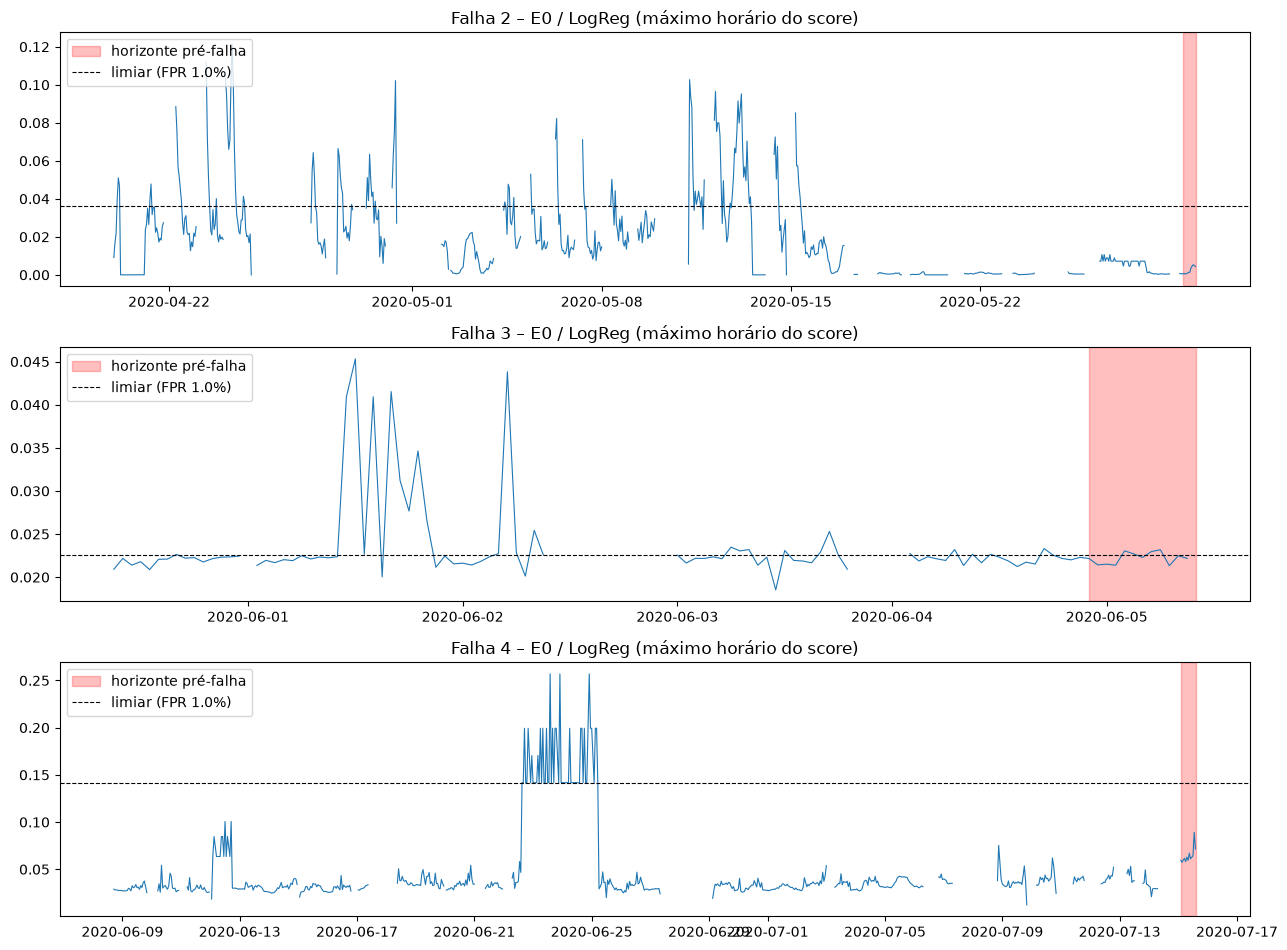

In [26]:
best = summary["lift_medio"].idxmax()
print("Melhor combinação:", best)
fig, axes = plt.subplots(len(folds), 1, figsize=(13, 3.2 * len(folds)), squeeze=False)
for ax, fold in zip(axes[:, 0], folds):
    key = (best[0], best[1], fold.test_failure_id)
    if key not in preds:
        ax.set_title(f"Falha {fold.test_failure_id}: sem dados"); continue
    t, thr = preds[key]
    hourly = t.set_index("ts")["score"].resample("1h").max()
    ax.plot(hourly.index, hourly.values, lw=0.8)
    pos = t[t["label"] == 1]
    if len(pos):
        ax.axvspan(pos["ts"].min(), pos["ts"].max(), color="red", alpha=0.25, label="horizonte pré-falha")
    ax.axhline(thr, color="k", ls="--", lw=0.8, label=f"limiar (FPR {FPR_TARGET:.1%})")
    ax.set_title(f"Falha {fold.test_failure_id} – {best[0]} / {best[1]} (máximo horário do score)")
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 6. Importância das features (LightGBM, E2, último fold)

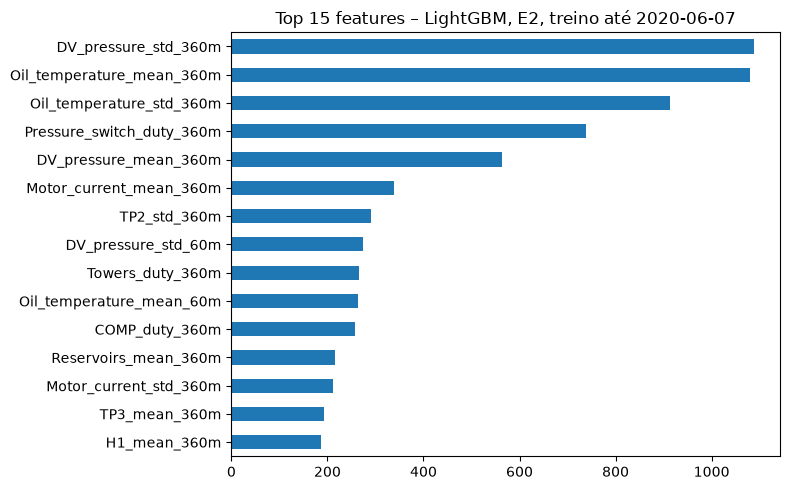

In [27]:
feats = feature_columns(data["E2"])
fold = folds[-1]
train = data["E2"][data["E2"]["ts"] <= fold.train_end]
model = make_models()["LightGBM"].fit(train[feats], train["label"])
imp = pd.Series(model.feature_importances_, index=feats).sort_values(ascending=False).head(15)
imp.iloc[::-1].plot(kind="barh", figsize=(8, 5), title=f"Top 15 features – LightGBM, E2, treino até {fold.train_end:%Y-%m-%d}")
plt.tight_layout()
plt.show()

- Algum modelo supera o acaso (lift > 1 e `p_pr_auc` baixo) de forma consistente nas falhas? Não. O melhor lift médio foi o E0 LogReg (2.645), mas a detecção esperada por acaso foi 1.325 e a detecção observada foi apenas 1 das 3 falhas testadas; o caso mais forte foi a falha 4, em que o E0 LogReg alcançou lift 6.38 com `p_pr_auc = 0.10`, mas ele foi isolado e não se repetiu nas outras falhas. O E2 LightGBM na falha 3 teve lift 1.23 com `p_pr_auc = 0.16`, mas também não apareceu de forma consistente em todos os folds. Portanto, não há evidência de sinal reproduzível acima do acaso; H1 e H2 seguem indeterminadas.
- A diferença entre variantes é maior que a diferença entre algoritmos (H2)? Não há evidência estável de que a engenharia de dados (E0 → E1 → E2) tenha mudado o desempenho de forma consistente. Os resultados variam bastante entre falhas e o contraste mais forte foi um caso isolado (E0 LogReg na falha 4), sem repetição. Em termos gerais, os algoritmos ficaram juntos na maior parte dos folds, perto da linha do acaso; o que apareceu foi muito mais um efeito de uma falha específica do que um ganho robusto da variante.
- Features em janelas ajudaram o recall e a antecedência (H1)? Não se pode afirmar isso com este desenho. As antecedências observadas quando houve detecção ficaram em torno de 17–22 horas, mas apareceram em apenas 1–2 casos e não vieram acompanhadas de `p_pr_auc` forte e repetição entre falhas. Sem uma melhora consistente em lift, recall e p_pr_auc, não há suporte para H1.
- Quantas das falhas testadas foram detectadas, com que antecedência e com quantos falsos alarmes por dia? Em 9 folds (3 variantes × 3 falhas), o total foi: LightGBM detectou 3 falhas, LogReg 2 e RandomForest 2. A maioria das detecções se concentrou na falha 3 e no caso isolado da falha 4 do E0 LogReg. Quando houve detecção, a antecedência foi de aproximadamente 17–22 horas; os falsos alarmes por dia variaram de ~0.07 a ~4.9, mas esse número é pouco informativo sem uma garantia de repetição em várias falhas. O conjunto de resultados é descritivo e não generalizável.
- Houve comportamento inesperado em alguma falha (a falha 4 tem menos positivos e comportamento diferente)? Sim: a falha 4 foi o caso mais atípico. Ela tem menos positivos no horizonte pré-falha (735 minutos, prevalência ~1.9%) e o E0 LogReg alcançou lift 6.38 com `p_pr_auc = 0.10`, mas esse padrão não se repetiu nas demais falhas nem nas outras variantes. Em contraste, a falha 2 ficou quase sempre abaixo de 1 em lift, e a falha 3 mostrou alguns modelos com lift acima de 1, mas sem sustentação consistente. Isso reforça a ideia de que o conjunto atual é muito pequeno e heterogêneo.
- Lembrar: 3 folds, 1 evento cada. Resultados descritivos, sem significância estatística. A amostra é pequena demais para separar “sinal real” de “caso isolado”.
- Próximas rodadas: `BALANCE = "class_weight"` (E3), seleção de features com GA (E4), teste de robustez com dados degradados (P2), e sensibilidade ao horizonte (6/12/48 h). Porém, essas rodadas só fazem sentido após aparecer um sinal consistente acima do acaso. Até lá, o mais prudente é adiar E3/E4/P2 e manter a avaliação focada na existência de sinal real no conjunto atual.